# 13 — Wind Direction & Neighbor Alignment Analysis

**Purpose:** test whether spatial activity in neighboring grid cells—and specifically activity aligned with the wind vector—adds predictive information for **next-day FIRMS hotspot detection** on the corrected Indonesian Kalimantan domain.

This notebook comes **before GAT**. It is a diagnostic notebook, not yet a graph neural network.

## Main question

> When recent local fire history is absent, does activity in nearby cells provide additional predictive information, and does wind direction improve that spatial signal?

## Analysis levels

### A. Overall next-day task
Compare:

1. corrected LR20 baseline;
2. LR20 + non-directional neighbor activity;
3. LR20 + neighbor activity + wind-aligned spatial signals.

### B. 3-day Emerging-eligible task
Restrict target rows to cells with **zero observed local activity during `t-2 ... t`**.

This creates a proper binary task:

- positive: hotspot detected at `t+1` after zero recent local activity;
- negative: no hotspot detected at `t+1` after zero recent local activity.

This allows PR-AUC / precision / recall to be calculated legitimately.

## Spatial graph sensitivity

Static directed neighbor graphs are evaluated at **100 km, 150 km, and 200 km**. `150 km` is the working graph for detailed diagnostics.

## Wind alignment

For an edge `source A → target B`, cosine alignment compares the source-cell wind vector `(wind_u_mean, wind_v_mean)` with the geographic direction from A to B.

- `+1`: wind points directly toward target B;
- `0`: approximately perpendicular;
- `-1`: opposite direction.

A positive result is interpreted as **predictive association**, not proof of physical flame spread or causality.

In [1]:
# 1. Imports and reproducibility

from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    precision_recall_curve,
)

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 150)
pd.set_option("display.width", 200)

print("Imports ready.")

Imports ready.


## 2. Resolve project paths

The notebook uses only the spatially corrected outputs from Notebook 12B/12C for its main analysis.

In [2]:
# 2. Project paths

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for candidate in candidate_roots:
    ml_candidate = (
        candidate
        / "data"
        / "processed"
        / "spatial_corrected"
        / "karhut_ml_dataset_kalimantan_corrected.csv"
    )
    node_candidate = (
        candidate
        / "data"
        / "intermediate"
        / "spatial_corrected"
        / "kalimantan_graph_nodes_corrected.csv"
    )
    if ml_candidate.exists() and node_candidate.exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root could not be detected automatically. "
        "Run Notebook 12B and 12C first."
    )

ML_INPUT = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spatial_corrected"
    / "karhut_ml_dataset_kalimantan_corrected.csv"
)

NODES_INPUT = (
    PROJECT_ROOT
    / "data"
    / "intermediate"
    / "spatial_corrected"
    / "kalimantan_graph_nodes_corrected.csv"
)

RESULTS_DIR = PROJECT_ROOT / "model_results" / "wind_neighbor_analysis"
FIGURES_DIR = RESULTS_DIR / "figures"
EDGES_DIR = RESULTS_DIR / "graph_edges"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
EDGES_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("ML input     :", ML_INPUT)
print("Nodes input  :", NODES_INPUT)
print("Results      :", RESULTS_DIR)

PROJECT_ROOT : c:\Users\Asus\Documents\skripsi-karhut
ML input     : c:\Users\Asus\Documents\skripsi-karhut\data\processed\spatial_corrected\karhut_ml_dataset_kalimantan_corrected.csv
Nodes input  : c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\spatial_corrected\kalimantan_graph_nodes_corrected.csv
Results      : c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis


In [3]:
# 3. Load corrected data

ml = pd.read_csv(ML_INPUT, parse_dates=["date"])
nodes = pd.read_csv(NODES_INPUT)

ml = ml.sort_values(["date", "cell_id"]).reset_index(drop=True)
nodes = nodes.sort_values("node_index").reset_index(drop=True)

print("Corrected ML shape :", ml.shape)
print("Corrected nodes    :", nodes.shape)
print("Date range         :", ml["date"].min().date(), "→", ml["date"].max().date())
print("ML unique cells    :", ml["cell_id"].nunique())
print("Node unique cells  :", nodes["cell_id"].nunique())

Corrected ML shape : (11340, 37)
Corrected nodes    : (90, 9)
Date range         : 2026-05-08 → 2026-09-10
ML unique cells    : 90
Node unique cells  : 90


## 4. Required-column and consistency audit

In [4]:
# 4. Integrity audit

weather_features = [
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "boundary_layer_height_mean",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_u_mean",
    "wind_v_mean",
]

fire_history_features = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

features_20 = fire_history_features + weather_features
target_col = "target_fire_active_t1"

required_ml = {
    "cell_id", "grid_lat", "grid_lon", "date",
    "fire_active", "fire_count", "frp_sum", target_col,
    "active_days_prev3_incl_t", "event_type_3d",
    *features_20,
}
missing_ml = sorted(required_ml - set(ml.columns))
if missing_ml:
    raise ValueError(f"Corrected ML file is missing columns: {missing_ml}")

required_nodes = {"node_index", "cell_id", "grid_lat", "grid_lon"}
missing_nodes = sorted(required_nodes - set(nodes.columns))
if missing_nodes:
    raise ValueError(f"Node file is missing columns: {missing_nodes}")

assert ml.duplicated(["cell_id", "date"]).sum() == 0
assert nodes["cell_id"].duplicated().sum() == 0

if set(ml["cell_id"].unique()) != set(nodes["cell_id"].unique()):
    raise AssertionError("ML cells and graph-node cells do not match.")

missing_features = ml[features_20].isna().sum().sum()

print("Duplicate ML cell-date rows:", ml.duplicated(["cell_id", "date"]).sum())
print("Missing benchmark features :", missing_features)
print("Node consistency           : PASSED")

Duplicate ML cell-date rows: 0
Missing benchmark features : 0
Node consistency           : PASSED


## 5. Wind-component diagnostic

The existing corrected table already contains daily `wind_u_mean` and `wind_v_mean`. Notebook 13 uses these vector components directly. `sqrt(u²+v²)` is calculated only as a diagnostic and is not expected to equal scalar `wind_speed_mean` exactly.

In [5]:
# 5. Wind diagnostics

ml["wind_vector_magnitude"] = np.hypot(
    ml["wind_u_mean"],
    ml["wind_v_mean"],
)

display(
    ml[
        ["wind_speed_mean", "wind_vector_magnitude", "wind_u_mean", "wind_v_mean"]
    ].describe()
)

print("Near-zero daily wind-vector rows:", int((ml["wind_vector_magnitude"] < 1e-8).sum()))

,wind_speed_mean,wind_vector_magnitude,wind_u_mean,wind_v_mean
count,11340.000000,11340.000000,11340.000000,11340.000000
mean,6.906821,5.275891,-1.761306,3.502033
std,5.363070,5.906539,4.616785,5.103155
min,1.433333,0.029568,-32.755209,-7.026401
25%,3.691667,1.440157,-2.413840,0.265874
50%,5.041667,3.035692,-0.664858,1.712018
75%,7.934375,6.826032,0.475763,5.439838
max,35.250000,34.735203,21.188986,32.710061


Near-zero daily wind-vector rows: 0


# PART A — Static graph geometry

## 6. Haversine distance and source→target direction

In [6]:
# 6. Geographic helpers

EARTH_RADIUS_KM = 6371.0088

def haversine_pair_km(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    )
    return EARTH_RADIUS_KM * 2 * np.arcsin(np.sqrt(a))


def source_to_target_direction(lat1, lon1, lat2, lon2):
    """Initial bearing plus local east/north unit-vector components."""
    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)
    dlon = np.radians(lon2 - lon1)

    x = np.sin(dlon) * np.cos(phi2)
    y = (
        np.cos(phi1) * np.sin(phi2)
        - np.sin(phi1) * np.cos(phi2) * np.cos(dlon)
    )

    bearing_rad = np.arctan2(x, y)
    bearing_deg = (np.degrees(bearing_rad) + 360) % 360
    east_unit = np.sin(bearing_rad)
    north_unit = np.cos(bearing_rad)

    return bearing_deg, east_unit, north_unit

In [7]:
# 7. Build all directed non-self node pairs

pair_rows = []
node_records = list(
    nodes[["node_index", "cell_id", "grid_lat", "grid_lon"]].itertuples(index=False)
)

for source in node_records:
    for target in node_records:
        if source.cell_id == target.cell_id:
            continue

        distance_km = haversine_pair_km(
            source.grid_lat, source.grid_lon,
            target.grid_lat, target.grid_lon,
        )

        bearing_deg, east_unit, north_unit = source_to_target_direction(
            source.grid_lat, source.grid_lon,
            target.grid_lat, target.grid_lon,
        )

        pair_rows.append({
            "source_node_index": source.node_index,
            "source_cell_id": source.cell_id,
            "source_lat": source.grid_lat,
            "source_lon": source.grid_lon,
            "target_node_index": target.node_index,
            "target_cell_id": target.cell_id,
            "target_lat": target.grid_lat,
            "target_lon": target.grid_lon,
            "distance_km": distance_km,
            "bearing_deg_from_north": bearing_deg,
            "east_unit": east_unit,
            "north_unit": north_unit,
        })

all_pairs = pd.DataFrame(pair_rows)

print("Directed non-self pairs:", len(all_pairs))
print(
    "Distance range:",
    round(all_pairs["distance_km"].min(), 2), "→",
    round(all_pairs["distance_km"].max(), 2), "km",
)
display(all_pairs.head())

Directed non-self pairs: 8010
Distance range: 83.14 → 1121.61 km


,source_node_index,source_cell_id,source_lat,source_lon,target_node_index,target_cell_id,target_lat,target_lon,distance_km,bearing_deg_from_north,east_unit,north_unit
0,0,Kalimantan_-3.75_114.75,-3.75,114.75,1,Kalimantan_-3.75_115.50,-3.75,115.50,83.217750,90.024527,1.000000,-0.000428
1,0,Kalimantan_-3.75_114.75,-3.75,114.75,2,Kalimantan_-3.00_110.25,-3.00,110.25,506.419935,279.341083,-0.986740,0.162311
2,0,Kalimantan_-3.75_114.75,-3.75,114.75,3,Kalimantan_-3.00_111.00,-3.00,111.00,424.527075,281.214632,-0.980906,0.194485
3,0,Kalimantan_-3.75_114.75,-3.75,114.75,4,Kalimantan_-3.00_111.75,-3.00,111.75,343.288074,283.968154,-0.970430,0.241383
4,0,Kalimantan_-3.75_114.75,-3.75,114.75,5,Kalimantan_-3.00_112.50,-3.00,112.50,263.308905,288.396233,-0.948897,0.315587


## 8. Radius-graph sensitivity: 100 / 150 / 200 km

In [8]:
# 8. Radius graphs

RADII_KM = [100, 150, 200]
WORKING_RADIUS_KM = 150

edge_tables = {}
graph_summary_rows = []

for radius in RADII_KM:
    edges = (
        all_pairs[all_pairs["distance_km"] <= radius]
        .copy()
        .reset_index(drop=True)
    )
    edge_tables[radius] = edges

    degree = (
        edges.groupby("source_cell_id").size()
        .reindex(nodes["cell_id"], fill_value=0)
    )

    graph_summary_rows.append({
        "Radius_km": radius,
        "Directed Edges": len(edges),
        "Mean Neighbors": degree.mean(),
        "Median Neighbors": degree.median(),
        "Min Neighbors": degree.min(),
        "Max Neighbors": degree.max(),
        "Isolated Nodes": int((degree == 0).sum()),
    })

graph_summary = pd.DataFrame(graph_summary_rows)
display(graph_summary)

,Radius_km,Directed Edges,Mean Neighbors,Median Neighbors,Min Neighbors,Max Neighbors,Isolated Nodes
0,100,306,3.400000,4.0,1,4,0
1,150,590,6.555556,7.0,3,8,0
2,200,1336,14.844444,15.0,6,20,0


In [9]:
# 9. Save static graph-edge tables

for radius, edges in edge_tables.items():
    path = EDGES_DIR / f"kalimantan_directed_edges_r{radius}km.csv"
    edges.to_csv(path, index=False)
    print("Saved:", path)

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\graph_edges\kalimantan_directed_edges_r100km.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\graph_edges\kalimantan_directed_edges_r150km.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\graph_edges\kalimantan_directed_edges_r200km.csv


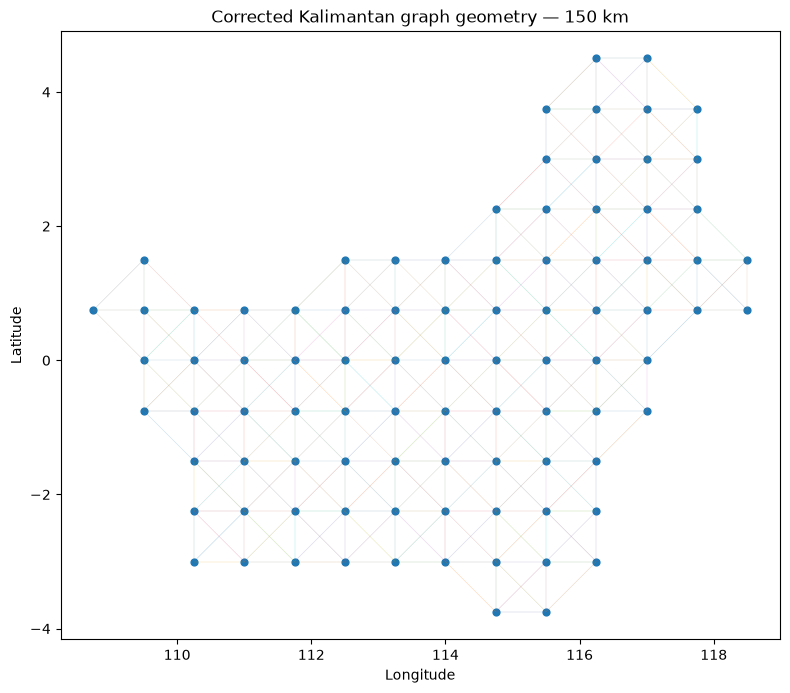

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\figures\01_graph_geometry_r150km.png


In [10]:
# 10. Graph geometry sanity plot for 150 km

working_edges = edge_tables[WORKING_RADIUS_KM]

fig, ax = plt.subplots(figsize=(8, 8))

for row in working_edges.itertuples(index=False):
    ax.plot(
        [row.source_lon, row.target_lon],
        [row.source_lat, row.target_lat],
        linewidth=0.35,
        alpha=0.18,
    )

ax.scatter(nodes["grid_lon"], nodes["grid_lat"], s=24)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"Corrected Kalimantan graph geometry — {WORKING_RADIUS_KM} km")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()

graph_fig = FIGURES_DIR / "01_graph_geometry_r150km.png"
plt.savefig(graph_fig, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", graph_fig)

# PART B — Dynamic spatial + wind features

## 11. Feature definitions

**Non-directional:** neighbor active count, neighbor fire-count/FRP summaries, and distance-decayed active signal.

**Directional:** aligned active count, opposing active count, positive wind-aligned signal, speed-weighted aligned signal, and mean alignment among active source neighbors.

`alignment >= 0.5` corresponds to source wind pointing within about 60° of the source→target direction.

In [11]:
# 11. Dynamic spatial feature builder

NONWIND_SPATIAL_FEATURES = [
    "neighbor_active_count",
    "neighbor_fire_count_log1p",
    "neighbor_frp_log1p",
    "neighbor_active_decay_signal",
]

WIND_SPATIAL_FEATURES = [
    "aligned_active_count",
    "opposing_active_count",
    "wind_aligned_active_signal",
    "wind_speed_aligned_active_signal",
    "mean_active_alignment",
]


def build_spatial_features(
    base_df,
    edges,
    radius_km,
    decay_scale_km=100.0,
    alignment_threshold=0.5,
):
    """Aggregate current-day source-neighbor activity into target-cell/day features."""

    source_daily = base_df[
        [
            "date", "cell_id", "fire_active", "fire_count", "frp_sum",
            "wind_u_mean", "wind_v_mean",
        ]
    ].copy()

    source_daily = source_daily.rename(columns={
        "cell_id": "source_cell_id",
        "fire_active": "source_fire_active",
        "fire_count": "source_fire_count",
        "frp_sum": "source_frp_sum",
        "wind_u_mean": "source_wind_u",
        "wind_v_mean": "source_wind_v",
    })

    edge_day = edges[
        ["source_cell_id", "target_cell_id", "distance_km", "east_unit", "north_unit"]
    ].merge(
        source_daily,
        on="source_cell_id",
        how="left",
        validate="many_to_many",
    )

    edge_day["wind_vector_magnitude"] = np.hypot(
        edge_day["source_wind_u"],
        edge_day["source_wind_v"],
    )

    numerator = (
        edge_day["source_wind_u"] * edge_day["east_unit"]
        + edge_day["source_wind_v"] * edge_day["north_unit"]
    )

    edge_day["wind_alignment"] = np.where(
        edge_day["wind_vector_magnitude"] > 1e-8,
        numerator / edge_day["wind_vector_magnitude"],
        0.0,
    )
    edge_day["wind_alignment"] = edge_day["wind_alignment"].clip(-1.0, 1.0)
    edge_day["positive_alignment"] = edge_day["wind_alignment"].clip(lower=0.0)
    edge_day["distance_decay"] = np.exp(-edge_day["distance_km"] / decay_scale_km)

    active = edge_day["source_fire_active"].astype(float)

    edge_day["active_decay_signal"] = active * edge_day["distance_decay"]
    edge_day["aligned_active"] = active * (
        edge_day["wind_alignment"] >= alignment_threshold
    ).astype(float)
    edge_day["opposing_active"] = active * (
        edge_day["wind_alignment"] <= -alignment_threshold
    ).astype(float)
    edge_day["wind_aligned_active"] = (
        active * edge_day["positive_alignment"] * edge_day["distance_decay"]
    )
    edge_day["wind_speed_aligned_active"] = (
        edge_day["wind_aligned_active"] * edge_day["wind_vector_magnitude"]
    )
    edge_day["active_alignment_numerator"] = active * edge_day["wind_alignment"]

    grouped = (
        edge_day
        .groupby(["date", "target_cell_id"], as_index=False)
        .agg(
            n_neighbors=("source_cell_id", "size"),
            neighbor_active_count=("source_fire_active", "sum"),
            neighbor_fire_count_sum=("source_fire_count", "sum"),
            neighbor_frp_sum=("source_frp_sum", "sum"),
            neighbor_active_decay_signal=("active_decay_signal", "sum"),
            aligned_active_count=("aligned_active", "sum"),
            opposing_active_count=("opposing_active", "sum"),
            wind_aligned_active_signal=("wind_aligned_active", "sum"),
            wind_speed_aligned_active_signal=("wind_speed_aligned_active", "sum"),
            active_alignment_sum=("active_alignment_numerator", "sum"),
        )
    )

    grouped["mean_active_alignment"] = np.where(
        grouped["neighbor_active_count"] > 0,
        grouped["active_alignment_sum"] / grouped["neighbor_active_count"],
        0.0,
    )
    grouped["neighbor_fire_count_log1p"] = np.log1p(grouped["neighbor_fire_count_sum"])
    grouped["neighbor_frp_log1p"] = np.log1p(grouped["neighbor_frp_sum"])
    grouped["radius_km"] = radius_km

    return grouped, edge_day

In [12]:
# 12. Build dynamic features for all radii

spatial_feature_tables = {}
edge_day_tables = {}
runtime_rows = []

for radius in RADII_KM:
    start = time.perf_counter()
    feature_table, edge_day = build_spatial_features(
        ml,
        edge_tables[radius],
        radius_km=radius,
    )
    seconds = time.perf_counter() - start

    spatial_feature_tables[radius] = feature_table
    edge_day_tables[radius] = edge_day

    runtime_rows.append({
        "Radius_km": radius,
        "Feature Rows": len(feature_table),
        "Edge-Day Rows": len(edge_day),
        "Runtime Seconds": seconds,
    })

runtime_summary = pd.DataFrame(runtime_rows)
display(runtime_summary)

,Radius_km,Feature Rows,Edge-Day Rows,Runtime Seconds
0,100,11340,38556,0.057808
1,150,11340,74340,0.071960
2,200,11340,168336,0.097488


In [13]:
# 13. Merge working 150-km features

spatial_150 = spatial_feature_tables[WORKING_RADIUS_KM].copy()

model_150 = ml.merge(
    spatial_150,
    left_on=["date", "cell_id"],
    right_on=["date", "target_cell_id"],
    how="left",
    validate="one_to_one",
)

fill_cols = NONWIND_SPATIAL_FEATURES + WIND_SPATIAL_FEATURES + ["n_neighbors"]
model_150[fill_cols] = model_150[fill_cols].fillna(0)

print("Merged model shape:", model_150.shape)

display(
    model_150[
        [
            "date", "cell_id", "fire_active", target_col,
            *NONWIND_SPATIAL_FEATURES,
            *WIND_SPATIAL_FEATURES,
        ]
    ].head()
)

Merged model shape: (11340, 53)


,date,cell_id,fire_active,target_fire_active_t1,neighbor_active_count,neighbor_fire_count_log1p,neighbor_frp_log1p,neighbor_active_decay_signal,aligned_active_count,opposing_active_count,wind_aligned_active_signal,wind_speed_aligned_active_signal,mean_active_alignment
0,2026-05-08,Kalimantan_-0.75_109.50,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2026-05-08,Kalimantan_-0.75_110.25,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2026-05-08,Kalimantan_-0.75_111.00,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2026-05-08,Kalimantan_-0.75_111.75,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2026-05-08,Kalimantan_-0.75_112.50,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
# 14. Spatial-feature sanity checks

assert not (working_edges["source_cell_id"] == working_edges["target_cell_id"]).any()

feature_check_cols = NONWIND_SPATIAL_FEATURES + WIND_SPATIAL_FEATURES
assert np.isfinite(model_150[feature_check_cols].to_numpy()).all()

print("Self-edges:", int((working_edges["source_cell_id"] == working_edges["target_cell_id"]).sum()))
print(
    "Mean-active-alignment range:",
    (model_150["mean_active_alignment"].min(), model_150["mean_active_alignment"].max()),
)
print("Spatial feature sanity checks: PASSED")

Self-edges: 0
Mean-active-alignment range: (np.float64(-0.9999995068612411), np.float64(0.9999996618723473))
Spatial feature sanity checks: PASSED


# PART C — Overall corrected next-day task

## 15. Temporal split

September remains unopened by default.

In [15]:
# 15. Temporal split

train_150 = model_150[model_150["date"] < "2026-08-01"].copy()
val_150 = model_150[
    (model_150["date"] >= "2026-08-01")
    & (model_150["date"] < "2026-09-01")
].copy()
test_150 = model_150[model_150["date"] >= "2026-09-01"].copy()

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [len(train_150), len(val_150), len(test_150)],
    "Positives": [
        int(train_150[target_col].sum()),
        int(val_150[target_col].sum()),
        int(test_150[target_col].sum()),
    ],
    "Positive Rate": [
        train_150[target_col].mean(),
        val_150[target_col].mean(),
        test_150[target_col].mean(),
    ],
})
display(split_summary)

,Split,Rows,Positives,Positive Rate
0,Train,7650,1786,0.233464
1,Validation,2790,2091,0.749462
2,Test,900,625,0.694444


In [16]:
# 16. LR helpers

def build_lr():
    return Pipeline([
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=RANDOM_STATE,
            ),
        ),
    ])


def evaluate_probabilities(y_true, probability, threshold=0.50):
    y_true = np.asarray(y_true).astype(int)
    probability = np.asarray(probability)
    prediction = (probability >= threshold).astype(int)

    return {
        "PR-AUC": average_precision_score(y_true, probability),
        "ROC-AUC": roc_auc_score(y_true, probability),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
        "Accuracy": accuracy_score(y_true, prediction),
        "Threshold": threshold,
    }


def fit_evaluate_lr(train_df, val_df, feature_cols, model_name):
    model = build_lr()
    start = time.perf_counter()
    model.fit(train_df[feature_cols], train_df[target_col].astype(int))
    train_seconds = time.perf_counter() - start

    probability = model.predict_proba(val_df[feature_cols])[:, 1]
    metrics = evaluate_probabilities(
        val_df[target_col].astype(int),
        probability,
        threshold=0.50,
    )

    result = {
        "Model": model_name,
        "N Features": len(feature_cols),
        **metrics,
        "Training Seconds": train_seconds,
    }
    return model, probability, result

## 17. Overall 150-km ablation

The key directional comparison is **LR20 + Neighbor + Wind** versus **LR20 + Neighbor**, because this isolates direction beyond generic neighbor activity.

In [17]:
# 17. Overall 150-km model ablation

overall_feature_sets = {
    "LR20": features_20,
    "LR20 + Neighbor": features_20 + NONWIND_SPATIAL_FEATURES,
    "LR20 + Neighbor + Wind": (
        features_20 + NONWIND_SPATIAL_FEATURES + WIND_SPATIAL_FEATURES
    ),
}

overall_models = {}
overall_probs = {}
overall_results = []

for name, cols in overall_feature_sets.items():
    model, probability, result = fit_evaluate_lr(
        train_150,
        val_150,
        cols,
        model_name=name,
    )
    overall_models[name] = model
    overall_probs[name] = probability
    overall_results.append(result)

overall_results_150 = pd.DataFrame(overall_results)
display(overall_results_150)

,Model,N Features,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Threshold,Training Seconds
0,LR20,20,0.955283,0.884426,0.866020,0.939742,0.901376,0.845878,0.5,0.134799
1,LR20 + Neighbor,24,0.956645,0.884517,0.806297,0.967480,0.879565,0.801434,0.5,0.074905
2,LR20 + Neighbor + Wind,29,0.956863,0.885130,0.806387,0.966045,0.879025,0.800717,0.5,0.080909


In [18]:
# 18. Overall incremental deltas

overall_indexed = overall_results_150.set_index("Model")

overall_neighbor_delta = (
    overall_indexed.loc["LR20 + Neighbor", "PR-AUC"]
    - overall_indexed.loc["LR20", "PR-AUC"]
)

overall_wind_delta = (
    overall_indexed.loc["LR20 + Neighbor + Wind", "PR-AUC"]
    - overall_indexed.loc["LR20 + Neighbor", "PR-AUC"]
)

print("Overall Neighbor Δ PR-AUC vs LR20:", f"{overall_neighbor_delta:+.6f}")
print("Overall Wind Δ PR-AUC beyond Neighbor:", f"{overall_wind_delta:+.6f}")

Overall Neighbor Δ PR-AUC vs LR20: +0.001362
Overall Wind Δ PR-AUC beyond Neighbor: +0.000218


# PART D — 3-day Emerging-eligible binary task

## 19. Define eligible rows

Eligible means `active_days_prev3_incl_t == 0`. Within that set, `target_fire_active_t1` is the binary target. This gives valid positives **and negatives** for PR-AUC.

In [20]:
# 19. Emerging-eligible subset

def emerging_eligible_subset(df):
    return df[df["active_days_prev3_incl_t"].eq(0)].copy()

eligible_train_150 = emerging_eligible_subset(train_150)
eligible_val_150 = emerging_eligible_subset(val_150)

eligible_summary = pd.DataFrame({
    "Split": ["Train", "Validation"],
    "Eligible Rows": [len(eligible_train_150), len(eligible_val_150)],
    "Positive Emerging": [
        int(eligible_train_150[target_col].sum()),
        int(eligible_val_150[target_col].sum()),
    ],
    "Positive Rate": [
        eligible_train_150[target_col].mean(),
        eligible_val_150[target_col].mean(),
    ],
})

display(eligible_summary)

validation_emerging_check = int(eligible_val_150[target_col].sum())
print("Validation eligible positives:", validation_emerging_check)

if validation_emerging_check != 61:
    print(
        "NOTE: Notebook 12C previously had 61 validation 3-day Emerging positives. "
        "A different value means the upstream corrected dataset changed."
    )

,Split,Eligible Rows,Positive Emerging,Positive Rate
0,Train,4742,432,0.091101
1,Validation,356,61,0.171348


Validation eligible positives: 61


## 20. Emerging-eligible ablation

Models:

1. local weather only;
2. local weather + non-directional neighbor activity;
3. local weather + neighbor activity + wind direction.

The longer local fire-history features are excluded from this specific diagnostic so the spatial question remains interpretable.

In [21]:
# 20. Eligible-task model ablation

eligible_feature_sets = {
    "Eligible — Local Weather": weather_features,
    "Eligible — Weather + Neighbor": weather_features + NONWIND_SPATIAL_FEATURES,
    "Eligible — Weather + Neighbor + Wind": (
        weather_features + NONWIND_SPATIAL_FEATURES + WIND_SPATIAL_FEATURES
    ),
}

eligible_models = {}
eligible_probs = {}
eligible_results = []

for name, cols in eligible_feature_sets.items():
    model, probability, result = fit_evaluate_lr(
        eligible_train_150,
        eligible_val_150,
        cols,
        model_name=name,
    )
    eligible_models[name] = model
    eligible_probs[name] = probability
    eligible_results.append(result)

eligible_results_150 = pd.DataFrame(eligible_results)
display(eligible_results_150)

,Model,N Features,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Threshold,Training Seconds
0,Eligible — Local Weather,10,0.270477,0.621339,0.217593,0.770492,0.339350,0.485955,0.5,0.031463
1,Eligible — Weather + Neighbor,14,0.273139,0.603890,0.186508,0.770492,0.300319,0.384831,0.5,0.033628
2,Eligible — Weather + Neighbor + Wind,19,0.295358,0.615532,0.191235,0.786885,0.307692,0.393258,0.5,0.051392


In [22]:
# 21. Primary eligible-task deltas

eligible_indexed = eligible_results_150.set_index("Model")

eligible_neighbor_delta = (
    eligible_indexed.loc["Eligible — Weather + Neighbor", "PR-AUC"]
    - eligible_indexed.loc["Eligible — Local Weather", "PR-AUC"]
)

eligible_wind_delta = (
    eligible_indexed.loc["Eligible — Weather + Neighbor + Wind", "PR-AUC"]
    - eligible_indexed.loc["Eligible — Weather + Neighbor", "PR-AUC"]
)

print("Eligible Neighbor Δ PR-AUC:", f"{eligible_neighbor_delta:+.6f}")
print("Eligible Wind Δ PR-AUC beyond Neighbor:", f"{eligible_wind_delta:+.6f}")

Eligible Neighbor Δ PR-AUC: +0.002662
Eligible Wind Δ PR-AUC beyond Neighbor: +0.022220


## 22. Descriptive spatial-signal comparison

These are descriptive validation associations only, not causal effects.

In [23]:
# 22. Raw signal summary

signal_cols = [
    "neighbor_active_count",
    "neighbor_active_decay_signal",
    "aligned_active_count",
    "opposing_active_count",
    "wind_aligned_active_signal",
    "wind_speed_aligned_active_signal",
    "mean_active_alignment",
]

descriptive_rows = []

for label_value, label_name in [(0, "Eligible Negative"), (1, "Emerging Positive")]:
    subset = eligible_val_150[eligible_val_150[target_col].eq(label_value)]

    for feature in signal_cols:
        descriptive_rows.append({
            "Group": label_name,
            "Feature": feature,
            "N": len(subset),
            "Mean": subset[feature].mean(),
            "Median": subset[feature].median(),
            "P75": subset[feature].quantile(0.75),
            "Max": subset[feature].max(),
        })

signal_descriptive = pd.DataFrame(descriptive_rows)
display(signal_descriptive)

,Group,Feature,N,Mean,Median,P75,Max
0,Eligible Negative,neighbor_active_count,295,2.464407,2.000000,4.000000,7.000000
1,Eligible Negative,neighbor_active_decay_signal,295,0.911976,0.742258,1.483740,2.660167
2,Eligible Negative,aligned_active_count,295,0.979661,1.000000,2.000000,4.000000
3,Eligible Negative,opposing_active_count,295,0.630508,0.000000,1.000000,4.000000
4,Eligible Negative,wind_aligned_active_signal,295,0.341846,0.292389,0.557862,1.393926
5,Eligible Negative,wind_speed_aligned_active_signal,295,1.218335,0.644236,1.683135,8.458078
6,Eligible Negative,mean_active_alignment,295,0.127679,0.060641,0.354604,0.997324
7,Emerging Positive,neighbor_active_count,61,3.032787,3.000000,4.000000,8.000000
8,Emerging Positive,neighbor_active_decay_signal,61,1.124143,1.049540,1.610721,2.967294
9,Emerging Positive,aligned_active_count,61,1.245902,1.000000,2.000000,4.000000


In [24]:
# 23. Univariate PR-AUC of raw spatial signals

y_eligible_val = eligible_val_150[target_col].astype(int).to_numpy()
univariate_rows = []

for feature in signal_cols:
    signal = eligible_val_150[feature].to_numpy()

    ap_positive = average_precision_score(y_eligible_val, signal)
    ap_negative = average_precision_score(y_eligible_val, -signal)

    if ap_positive >= ap_negative:
        direction = "higher → more positive"
        best_ap = ap_positive
    else:
        direction = "lower → more positive"
        best_ap = ap_negative

    univariate_rows.append({
        "Feature": feature,
        "PR-AUC raw": ap_positive,
        "PR-AUC sign-flipped": ap_negative,
        "Best Orientation": direction,
        "Best Univariate PR-AUC": best_ap,
    })

univariate_signal_results = (
    pd.DataFrame(univariate_rows)
    .sort_values("Best Univariate PR-AUC", ascending=False)
    .reset_index(drop=True)
)

display(univariate_signal_results)

,Feature,PR-AUC raw,PR-AUC sign-flipped,Best Orientation,Best Univariate PR-AUC
0,wind_speed_aligned_active_signal,0.276156,0.146674,higher → more positive,0.276156
1,neighbor_active_decay_signal,0.266660,0.151031,higher → more positive,0.266660
2,wind_aligned_active_signal,0.246986,0.159282,higher → more positive,0.246986
3,neighbor_active_count,0.239735,0.149689,higher → more positive,0.239735
4,opposing_active_count,0.225368,0.160600,higher → more positive,0.225368
5,aligned_active_count,0.225138,0.158739,higher → more positive,0.225138
6,mean_active_alignment,0.192378,0.193696,lower → more positive,0.193696


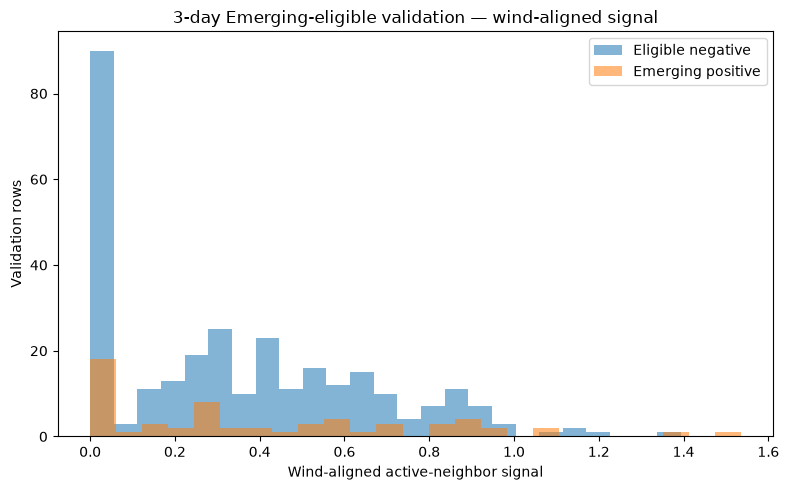

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\figures\02_eligible_wind_aligned_signal.png


In [25]:
# 24. Wind-aligned signal histogram

negative_signal = eligible_val_150.loc[
    eligible_val_150[target_col].eq(0),
    "wind_aligned_active_signal",
]
positive_signal = eligible_val_150.loc[
    eligible_val_150[target_col].eq(1),
    "wind_aligned_active_signal",
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(negative_signal, bins=25, alpha=0.55, label="Eligible negative")
ax.hist(positive_signal, bins=25, alpha=0.55, label="Emerging positive")
ax.set_xlabel("Wind-aligned active-neighbor signal")
ax.set_ylabel("Validation rows")
ax.set_title("3-day Emerging-eligible validation — wind-aligned signal")
ax.legend()
plt.tight_layout()

signal_fig = FIGURES_DIR / "02_eligible_wind_aligned_signal.png"
plt.savefig(signal_fig, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", signal_fig)

# PART E — Radius sensitivity

## 25. Re-evaluate all model ablations at 100 / 150 / 200 km

This is a sensitivity analysis, not a request to tune aggressively to validation.

In [26]:
# 25. Radius-sensitivity evaluation

radius_result_rows = []

for radius in RADII_KM:
    spatial_features = spatial_feature_tables[radius]

    data_r = ml.merge(
        spatial_features,
        left_on=["date", "cell_id"],
        right_on=["date", "target_cell_id"],
        how="left",
        validate="one_to_one",
    )

    fill_cols = NONWIND_SPATIAL_FEATURES + WIND_SPATIAL_FEATURES + ["n_neighbors"]
    data_r[fill_cols] = data_r[fill_cols].fillna(0)

    train_r = data_r[data_r["date"] < "2026-08-01"].copy()
    val_r = data_r[
        (data_r["date"] >= "2026-08-01")
        & (data_r["date"] < "2026-09-01")
    ].copy()

    eligible_train_r = emerging_eligible_subset(train_r)
    eligible_val_r = emerging_eligible_subset(val_r)

    model_specs = {
        "Overall LR20": (train_r, val_r, features_20, "Overall"),
        "Overall + Neighbor": (
            train_r, val_r,
            features_20 + NONWIND_SPATIAL_FEATURES,
            "Overall",
        ),
        "Overall + Neighbor + Wind": (
            train_r, val_r,
            features_20 + NONWIND_SPATIAL_FEATURES + WIND_SPATIAL_FEATURES,
            "Overall",
        ),
        "Eligible Weather": (
            eligible_train_r, eligible_val_r,
            weather_features,
            "Eligible 3d",
        ),
        "Eligible Weather + Neighbor": (
            eligible_train_r, eligible_val_r,
            weather_features + NONWIND_SPATIAL_FEATURES,
            "Eligible 3d",
        ),
        "Eligible Weather + Neighbor + Wind": (
            eligible_train_r, eligible_val_r,
            weather_features + NONWIND_SPATIAL_FEATURES + WIND_SPATIAL_FEATURES,
            "Eligible 3d",
        ),
    }

    for model_name, (tr, va, cols, task) in model_specs.items():
        _, _, result = fit_evaluate_lr(tr, va, cols, model_name=model_name)
        radius_result_rows.append({
            "Radius_km": radius,
            "Task": task,
            **result,
        })

radius_results = pd.DataFrame(radius_result_rows)

display(
    radius_results[
        ["Radius_km", "Task", "Model", "PR-AUC", "Precision", "Recall", "F1"]
    ]
)

,Radius_km,Task,Model,PR-AUC,Precision,Recall,F1
0,100,Overall,Overall LR20,0.955283,0.866020,0.939742,0.901376
1,100,Overall,Overall + Neighbor,0.956481,0.814860,0.959828,0.881423
2,100,Overall,Overall + Neighbor + Wind,0.956433,0.813869,0.959828,0.880843
3,100,Eligible 3d,Eligible Weather,0.270477,0.217593,0.770492,0.339350
4,100,Eligible 3d,Eligible Weather + Neighbor,0.275480,0.186722,0.737705,0.298013
5,100,Eligible 3d,Eligible Weather + Neighbor + Wind,0.273035,0.183673,0.737705,0.294118
6,150,Overall,Overall LR20,0.955283,0.866020,0.939742,0.901376
7,150,Overall,Overall + Neighbor,0.956645,0.806297,0.967480,0.879565
8,150,Overall,Overall + Neighbor + Wind,0.956863,0.806387,0.966045,0.879025
9,150,Eligible 3d,Eligible Weather,0.270477,0.217593,0.770492,0.339350


In [27]:
# 26. Radius delta summary

delta_rows = []

for radius in RADII_KM:
    sub = radius_results[radius_results["Radius_km"].eq(radius)].set_index("Model")

    delta_rows.append({
        "Radius_km": radius,
        "Overall Neighbor Δ PR-AUC": (
            sub.loc["Overall + Neighbor", "PR-AUC"]
            - sub.loc["Overall LR20", "PR-AUC"]
        ),
        "Overall Wind Δ PR-AUC": (
            sub.loc["Overall + Neighbor + Wind", "PR-AUC"]
            - sub.loc["Overall + Neighbor", "PR-AUC"]
        ),
        "Eligible Neighbor Δ PR-AUC": (
            sub.loc["Eligible Weather + Neighbor", "PR-AUC"]
            - sub.loc["Eligible Weather", "PR-AUC"]
        ),
        "Eligible Wind Δ PR-AUC": (
            sub.loc["Eligible Weather + Neighbor + Wind", "PR-AUC"]
            - sub.loc["Eligible Weather + Neighbor", "PR-AUC"]
        ),
    })

radius_delta_summary = pd.DataFrame(delta_rows)
display(radius_delta_summary)

,Radius_km,Overall Neighbor Δ PR-AUC,Overall Wind Δ PR-AUC,Eligible Neighbor Δ PR-AUC,Eligible Wind Δ PR-AUC
0,100,0.001199,-0.000048,0.005004,-0.002445
1,150,0.001362,0.000218,0.002662,0.022220
2,200,0.000673,0.000124,-0.003927,0.014387


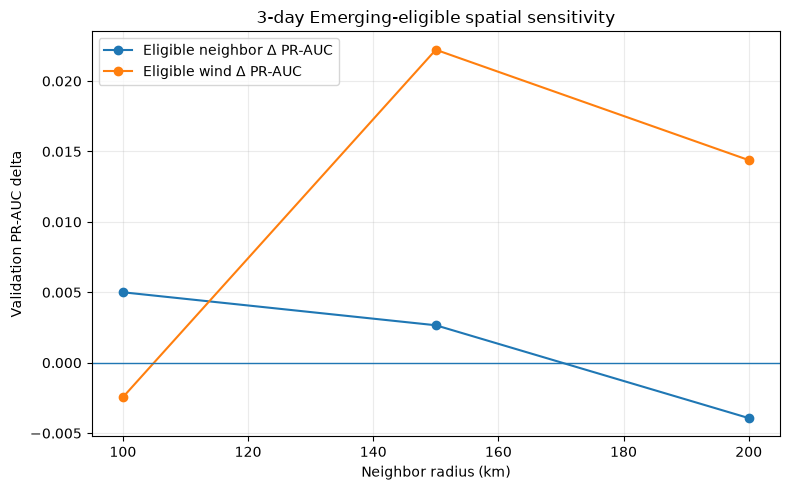

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\figures\03_radius_sensitivity_eligible.png


In [28]:
# 27. Radius sensitivity figure

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    radius_delta_summary["Radius_km"],
    radius_delta_summary["Eligible Neighbor Δ PR-AUC"],
    marker="o",
    label="Eligible neighbor Δ PR-AUC",
)
ax.plot(
    radius_delta_summary["Radius_km"],
    radius_delta_summary["Eligible Wind Δ PR-AUC"],
    marker="o",
    label="Eligible wind Δ PR-AUC",
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("Neighbor radius (km)")
ax.set_ylabel("Validation PR-AUC delta")
ax.set_title("3-day Emerging-eligible spatial sensitivity")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()

radius_fig = FIGURES_DIR / "03_radius_sensitivity_eligible.png"
plt.savefig(radius_fig, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", radius_fig)

# PART F — Save graph-ready outputs

In [29]:
# 28. Save working 150-km enriched table

spatial_output_cols = [
    "date", "cell_id", "target_cell_id", "n_neighbors",
    *NONWIND_SPATIAL_FEATURES,
    *WIND_SPATIAL_FEATURES,
]
spatial_output_cols = [c for c in spatial_output_cols if c in model_150.columns]

spatial_output_path = RESULTS_DIR / "corrected_ml_spatial_wind_r150km.csv"
model_150[spatial_output_cols].to_csv(spatial_output_path, index=False)
print("Saved:", spatial_output_path)

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\corrected_ml_spatial_wind_r150km.csv


In [30]:
# 29. Save diagnostic tables

output_tables = {
    "graph_radius_summary.csv": graph_summary,
    "spatial_feature_runtime.csv": runtime_summary,
    "overall_ablation_r150km.csv": overall_results_150,
    "eligible_ablation_r150km.csv": eligible_results_150,
    "eligible_signal_descriptive.csv": signal_descriptive,
    "eligible_univariate_signals.csv": univariate_signal_results,
    "radius_model_results.csv": radius_results,
    "radius_delta_summary.csv": radius_delta_summary,
    "eligible_task_summary.csv": eligible_summary,
}

for filename, dataframe in output_tables.items():
    path = RESULTS_DIR / filename
    dataframe.to_csv(path, index=False)
    print("Saved:", path)

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\graph_radius_summary.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\spatial_feature_runtime.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\overall_ablation_r150km.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\eligible_ablation_r150km.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\eligible_signal_descriptive.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\eligible_univariate_signals.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\radius_model_results.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\radius_delta_summary.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\wind_neighbor_analysis\eligible_task_summary.csv


# PART G — Keep September test unopened

In [31]:
# 30. Test lock

RUN_TEST = False

if RUN_TEST:
    print(
        "Final-test evaluation is intentionally not implemented here. "
        "Lock the graph/model design before opening September."
    )
else:
    print("RUN_TEST=False → September test probabilities remain uninspected.")

RUN_TEST=False → September test probabilities remain uninspected.


# 31. Automatic interpretation summary

This cell answers the practical design question for the next notebook:

- does generic neighboring activity help?
- does wind direction add information **beyond** generic neighbors?
- is any wind gain reasonably consistent across radii?

In [32]:
# 31. Automatic interpretation

eligible_wind_deltas = radius_delta_summary["Eligible Wind Δ PR-AUC"]
n_positive_wind_radii = int((eligible_wind_deltas > 0).sum())

eligible_val_positive_n = int(eligible_val_150[target_col].sum())
eligible_val_rows = len(eligible_val_150)
eligible_base_rate = eligible_val_150[target_col].mean()

print("=== Notebook 13 wind + neighbor diagnostic ===")
print()
print("GRAPH")
print("Corrected nodes              :", len(nodes))
print("Working radius               :", WORKING_RADIUS_KM, "km")
print("Working directed edges       :", len(working_edges))
print()
print("OVERALL TASK — 150 km")
print("Neighbor Δ PR-AUC vs LR20    :", f"{overall_neighbor_delta:+.6f}")
print("Wind Δ PR-AUC beyond neighbor:", f"{overall_wind_delta:+.6f}")
print()
print("3-DAY EMERGING-ELIGIBLE — 150 km")
print("Validation eligible rows     :", eligible_val_rows)
print("Validation Emerging positives:", eligible_val_positive_n)
print("Eligible positive rate       :", round(eligible_base_rate, 6))
print("Neighbor Δ PR-AUC            :", f"{eligible_neighbor_delta:+.6f}")
print("Wind Δ PR-AUC beyond neighbor:", f"{eligible_wind_delta:+.6f}")
print()
print("RADIUS ROBUSTNESS")
print("Positive eligible wind deltas:", f"{n_positive_wind_radii}/{len(RADII_KM)} radii")
print()

if eligible_neighbor_delta > 0:
    print(
        "Neighbor activity provides additional predictive information for the "
        "3-day Emerging-eligible task at 150 km."
    )
else:
    print(
        "Neighbor activity does not improve the 3-day Emerging-eligible PR-AUC "
        "at 150 km."
    )

if eligible_wind_delta > 0 and n_positive_wind_radii == len(RADII_KM):
    print(
        "Wind-direction features add positive validation PR-AUC beyond generic "
        "neighbor activity across all tested radii. Wind-informed graph edges "
        "are justified as a candidate ablation."
    )
elif eligible_wind_delta > 0:
    print(
        "Wind direction adds some validation skill at 150 km, but the effect is "
        "not consistently positive across all radii. Treat wind-informed edges "
        "as exploratory."
    )
else:
    print(
        "Wind direction does not improve 150-km eligible-task PR-AUC beyond generic "
        "neighbor activity. Do not force wind into the GAT architecture."
    )

print()
print(
    "NEXT: if neighbor information is useful, proceed to a graph baseline and then "
    "temporal GAT. Include wind edge information only if this notebook shows a "
    "stable incremental signal."
)

=== Notebook 13 wind + neighbor diagnostic ===

GRAPH
Corrected nodes              : 90
Working radius               : 150 km
Working directed edges       : 590

OVERALL TASK — 150 km
Neighbor Δ PR-AUC vs LR20    : +0.001362
Wind Δ PR-AUC beyond neighbor: +0.000218

3-DAY EMERGING-ELIGIBLE — 150 km
Validation eligible rows     : 356
Validation Emerging positives: 61
Eligible positive rate       : 0.171348
Neighbor Δ PR-AUC            : +0.002662
Wind Δ PR-AUC beyond neighbor: +0.022220

RADIUS ROBUSTNESS
Positive eligible wind deltas: 2/3 radii

Neighbor activity provides additional predictive information for the 3-day Emerging-eligible task at 150 km.
Wind direction adds some validation skill at 150 km, but the effect is not consistently positive across all radii. Treat wind-informed edges as exploratory.

NEXT: if neighbor information is useful, proceed to a graph baseline and then temporal GAT. Include wind edge information only if this notebook shows a stable incremental signal.


# What to send for review

After running Notebook 13, send:

1. **Section 8** — graph-radius summary
2. **Section 17** — overall 150-km ablation
3. **Section 20** — Emerging-eligible ablation
4. **Section 21** — neighbor and wind PR-AUC deltas
5. **Section 22–23** — raw signal diagnostics
6. **Section 26** — radius delta summary
7. **Section 31** — automatic interpretation

Also send screenshots of:

- `02_eligible_wind_aligned_signal.png`
- `03_radius_sensitivity_eligible.png`

## Decision after Notebook 13

- **Neighbor helps + wind consistently helps:** proceed to graph baseline → GAT → temporal GAT → wind-informed ablation.
- **Neighbor helps but wind does not:** proceed to graph baseline → GAT → temporal GAT without forcing wind.
- **Neither helps:** reconsider spatial resolution / graph definition before investing in GAT.